# AulaSense: propuesta de arquitectura por capas
**Autor:** David Atilano  
**Materia:** Ingeniería en Software · Universidad Politécnica de Querétaro  
**Rama:** `david-capas`  
**Archivo:** `02-propuestas/david-capas/01_david_capas.ipynb`

## 1. Descripción de la propuesta
Separar el servidor de AulaSense en cuatro capas: **recepción**, **lógica de negocio**, **acceso a datos** y **presentación**. Cada capa tiene una responsabilidad concreta y se comunica mediante métodos explícitos. Se conserva un recorrido síncrono: una lectura se recibe, se interpreta, se almacena y después puede consultarse.

El objetivo principal es mejorar el diseño; el ejemplo Python es una demostración educativa con datos simulados, sin sensores físicos, servidor web ni base de datos externa.

## 2. Problema de diseño que resuelve
El notebook `01-analisis-original/diseno_original.ipynb` describe un **diseño original supuesto**, no una implementación verificada. Su clase `SistemaAulaSense` reúne recepción, validación, procesamiento, persistencia, alertas, visualización, administración y dispositivos. Por ello, los problemas siguientes son riesgos del diseño, no defectos medidos en producción.

- **Baja cohesión:** una misma clase atiende responsabilidades que cambian por motivos distintos.
- **Alto acoplamiento:** cambiar el almacenamiento o el dashboard puede afectar la clase central.
- **Pruebas difíciles:** comprobar reglas de ocupación puede exigir preparar también almacenamiento e interfaz.
- **Crecimiento de la clase:** nuevos sensores y funciones agregan más métodos al mismo componente.

Esta propuesta desarrolla el flujo de mediciones ambientales y presencia. Usuarios, permisos y registro de dispositivos quedan fuera del ejemplo y requerirían servicios propios. No se afirma resolver todas las responsabilidades del sistema con estas cinco clases.

## 3. Capas, clases, responsabilidades y métodos
| Capa | Clase | Responsabilidad | Métodos principales |
|---|---|---|---|
| Recepción | `ReceptorLecturas` | Validar estructura, tipos, fecha y rangos del mensaje; construir una lectura y delegar | `recibir(datos)` |
| Lógica de negocio | `ServicioMonitoreo` | Estimar ocupación, aplicar umbral de CO₂, registrar y consultar mediciones | `registrar(lectura)`, `consultar(aula)` |
| Acceso a datos: contrato | `RepositorioMediciones` | Definir operaciones de persistencia sin imponer tecnología | `guardar(medicion)`, `listar_por_aula(aula)` |
| Acceso a datos: implementación | `RepositorioEnMemoria` | Guardar registros durante la ejecución del notebook | `guardar(medicion)`, `listar_por_aula(aula)` |
| Presentación | `Dashboard` | Convertir resultados del servicio en un resumen legible | `mostrar(aula)` |
| Modelo compartido | `Lectura`, `Medicion` | Representar datos de entrada y resultados inmutables | Constructores de datos |

**Reglas de comunicación:** recepción → servicio; presentación → servicio; servicio → contrato de repositorio. La implementación en memoria cumple ese contrato. Recepción y presentación son dos entradas al servicio: el dashboard no recibe mensajes del sensor y no consulta directamente el repositorio. Los modelos compartidos no coordinan operaciones.

La validación de formato y rangos físicos pertenece a recepción. La estimación de ocupación y la decisión de alerta pertenecen al negocio. Un CO₂ de 1200 ppm es una regla de ejemplo configurable, no una recomendación sanitaria. Presencia permite clasificar un aula como ocupada o libre; no permite contar personas.

## 4. Diagrama de clases mejorado
El diagrama siguiente se genera en Python y queda guardado como salida del notebook para visualizarlo también en GitHub. Las flechas sólidas representan uso; la discontinua representa implementación de un contrato abstracto. No hay herencia entre las capas. `Lectura` y `Medicion` son objetos compartidos por los componentes que los necesitan.


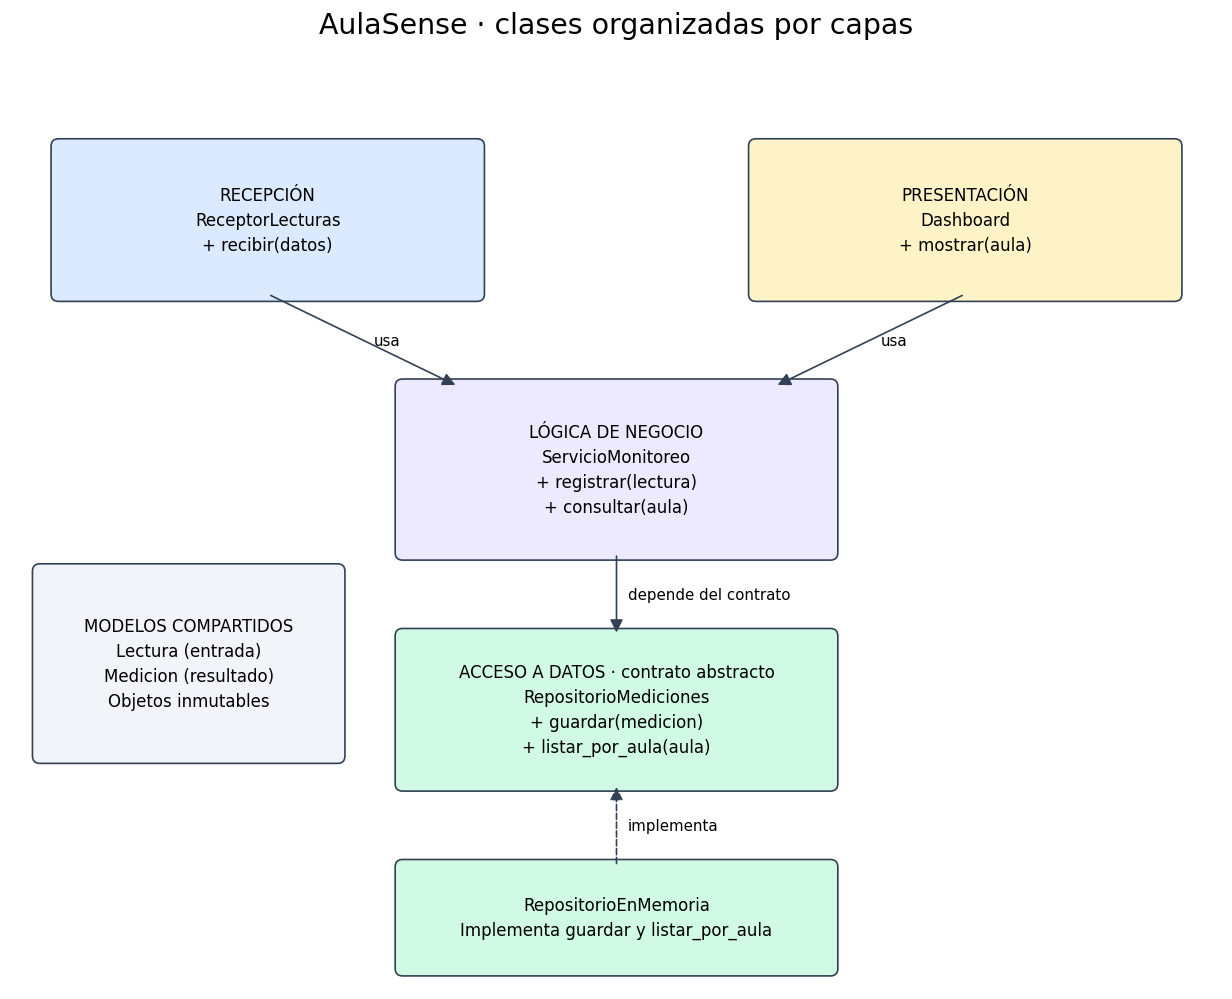

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13, 10))
ax.set_xlim(0, 13); ax.set_ylim(0, 10); ax.axis('off')
def caja(x, y, w, h, texto, color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.08',
                              facecolor=color,edgecolor='#334155'))
    ax.text(x+w/2,y+h/2,texto,ha='center',va='center',fontsize=10,linespacing=1.5)
def relacion(a,b,texto='',discontinua=False):
    ax.add_patch(FancyArrowPatch(a,b,arrowstyle='-|>',mutation_scale=16,
                                linestyle='--' if discontinua else '-',color='#334155'))
    ax.text((a[0]+b[0])/2+0.12,(a[1]+b[1])/2,texto,fontsize=9,va='center')
caja(.5,7.5,4.5,1.6,'RECEPCIÓN\nReceptorLecturas\n+ recibir(datos)', '#DBEAFE')
caja(8,7.5,4.5,1.6,'PRESENTACIÓN\nDashboard\n+ mostrar(aula)', '#FEF3C7')
caja(4.2,4.7,4.6,1.8,'LÓGICA DE NEGOCIO\nServicioMonitoreo\n+ registrar(lectura)\n+ consultar(aula)', '#EDE9FE')
caja(4.2,2.2,4.6,1.6,'ACCESO A DATOS · contrato abstracto\nRepositorioMediciones\n+ guardar(medicion)\n+ listar_por_aula(aula)', '#D1FAE5')
caja(4.2,.2,4.6,1.1,'RepositorioEnMemoria\nImplementa guardar y listar_por_aula', '#D1FAE5')
caja(.3,2.5,3.2,2,'MODELOS COMPARTIDOS\nLectura (entrada)\nMedicion (resultado)\nObjetos inmutables', '#F1F5F9')
relacion((2.75,7.5),(4.8,6.5),'usa')
relacion((10.25,7.5),(8.2,6.5),'usa')
relacion((6.5,4.7),(6.5,3.8),'depende del contrato')
relacion((6.5,1.3),(6.5,2.2),'implementa',True)
ax.set_title('AulaSense · clases organizadas por capas',fontsize=17,pad=18)
plt.show()


### Relaciones y recorrido
1. El sensor simulado entrega un diccionario a `ReceptorLecturas.recibir`.
2. El receptor comprueba los datos y crea `Lectura`.
3. `ServicioMonitoreo.registrar` produce una `Medicion` con ocupación y alerta.
4. El servicio solicita `guardar` al repositorio inyectado y devuelve el resultado.
5. `Dashboard.mostrar` pide al servicio el historial de un aula y presenta un resumen.

Un servicio utiliza un repositorio; recepción y dashboard comparten la misma instancia de servicio. El repositorio conserva cero o muchas mediciones. La dependencia del contrato permite cambiar la tecnología de almacenamiento sin modificar recepción ni presentación.

## 5. Código Python de la propuesta
Se utilizan `dataclass` inmutables y un contrato abstracto de la biblioteca estándar. La inyección por constructor hace visibles las dependencias. El diagrama requiere Matplotlib; el flujo y las pruebas no requieren paquetes adicionales.


In [2]:
from abc import ABC, abstractmethod
from dataclasses import dataclass
from datetime import datetime
from math import isfinite

@dataclass(frozen=True)
class Lectura:
    aula: str
    instante: datetime
    temperatura: float
    humedad: float
    co2: float
    presencia: bool

@dataclass(frozen=True)
class Medicion:
    lectura: Lectura
    ocupacion: str
    alerta_co2: bool

class RepositorioMediciones(ABC):
    @abstractmethod
    def guardar(self, medicion: Medicion) -> None:
        pass

    @abstractmethod
    def listar_por_aula(self, aula: str) -> list[Medicion]:
        pass

class RepositorioEnMemoria(RepositorioMediciones):
    def __init__(self):
        self._mediciones = []

    def guardar(self, medicion):
        self._mediciones.append(medicion)

    def listar_por_aula(self, aula):
        return [m for m in self._mediciones if m.lectura.aula == aula]

class ServicioMonitoreo:
    def __init__(self, repositorio: RepositorioMediciones, umbral_co2=1200):
        if (type(umbral_co2) not in (int, float)
                or not isfinite(umbral_co2) or umbral_co2 <= 0):
            raise ValueError('El umbral de CO₂ debe ser positivo y finito')
        self._repositorio = repositorio
        self._umbral_co2 = umbral_co2

    def registrar(self, lectura: Lectura) -> Medicion:
        medicion = Medicion(lectura,
                            'ocupada' if lectura.presencia else 'libre',
                            lectura.co2 > self._umbral_co2)
        self._repositorio.guardar(medicion)
        return medicion

    def consultar(self, aula: str) -> list[Medicion]:
        return self._repositorio.listar_por_aula(aula)

class ReceptorLecturas:
    def __init__(self, servicio: ServicioMonitoreo):
        self._servicio = servicio

    def recibir(self, datos: dict) -> Medicion:
        campos = {'aula', 'instante', 'temperatura', 'humedad', 'co2', 'presencia'}
        if not isinstance(datos, dict) or not campos.issubset(datos):
            raise ValueError('Mensaje incompleto o con formato incorrecto')
        if not isinstance(datos['aula'], str) or not datos['aula'].strip():
            raise ValueError('Aula inválida')
        if type(datos['presencia']) is not bool:
            raise ValueError('Presencia debe ser un booleano')
        # Rangos ilustrativos para esta simulación; se ajustarían al sensor real.
        for campo, minimo, maximo in [('temperatura', -40, 85),
                                       ('humedad', 0, 100), ('co2', 0, 10000)]:
            valor = datos[campo]
            if (type(valor) not in (int, float) or not isfinite(valor)
                    or not minimo <= valor <= maximo):
                raise ValueError(f'{campo} fuera de rango o no numérico')
        try:
            instante = datetime.fromisoformat(datos['instante'])
        except (TypeError, ValueError):
            raise ValueError('Instante debe ser una fecha ISO 8601') from None
        if instante.tzinfo is None or instante.utcoffset() is None:
            raise ValueError('Instante debe incluir zona horaria')
        lectura = Lectura(datos['aula'].strip(), instante,
                          float(datos['temperatura']), float(datos['humedad']),
                          float(datos['co2']), datos['presencia'])
        return self._servicio.registrar(lectura)

class Dashboard:
    def __init__(self, servicio: ServicioMonitoreo):
        self._servicio = servicio

    def mostrar(self, aula: str) -> str:
        mediciones = self._servicio.consultar(aula)
        if not mediciones:
            return f'{aula}: sin mediciones'
        ultima = max(mediciones, key=lambda m: m.lectura.instante)
        return (f'{aula}: {len(mediciones)} mediciones | '
                f'última ocupación: {ultima.ocupacion} | '
                f'alertas CO₂: {sum(m.alerta_co2 for m in mediciones)}')


## 6. Demostración con datos simulados
El montaje se realiza fuera de las clases: así se evita que el servicio cree su almacenamiento o que el dashboard conozca detalles de persistencia. Se simulan dos lecturas del aula A-101 y una de B-202. Las fechas incluyen el desplazamiento horario de México. La alerta se activa **por encima** de 1200 ppm.


In [3]:
repositorio = RepositorioEnMemoria()
servicio = ServicioMonitoreo(repositorio, umbral_co2=1200)
receptor = ReceptorLecturas(servicio)
dashboard = Dashboard(servicio)

simulados = [
    dict(aula='A-101', instante='2026-10-16T09:00:00-06:00',
         temperatura=24, humedad=45, co2=800, presencia=False),
    dict(aula='A-101', instante='2026-10-16T09:05:00-06:00',
         temperatura=26, humedad=50, co2=1500, presencia=True),
    dict(aula='B-202', instante='2026-10-16T09:10:00-06:00',
         temperatura=23, humedad=48, co2=700, presencia=True),
]
for datos in simulados:
    resultado = receptor.recibir(datos)
    print(f'{resultado.lectura.aula}: guardada, '
          f'{resultado.ocupacion}, alerta CO₂={resultado.alerta_co2}')
print(dashboard.mostrar('A-101'))
print(dashboard.mostrar('B-202'))
print(dashboard.mostrar('C-303'))


A-101: guardada, libre, alerta CO₂=False
A-101: guardada, ocupada, alerta CO₂=True
B-202: guardada, ocupada, alerta CO₂=False
A-101: 2 mediciones | última ocupación: ocupada | alertas CO₂: 1
B-202: 1 mediciones | última ocupación: ocupada | alertas CO₂: 0
C-303: sin mediciones


## 7. Pruebas sencillas
Las pruebas verifican comportamiento: separación de aulas, reglas de ocupación y alerta, rechazo sin almacenamiento de mensajes inválidos, selección de la fecha más reciente e independencia del servicio frente al repositorio concreto. Cada prueba prepara sus propios objetos y puede repetirse.


In [4]:
def ejecutar_pruebas():
    repo = RepositorioEnMemoria()
    srv = ServicioMonitoreo(repo)
    entrada = ReceptorLecturas(srv)
    vista = Dashboard(srv)
    base = dict(simulados[0])
    assert entrada.recibir(base).ocupacion == 'libre'
    limite = entrada.recibir({**base, 'co2': 1200, 'presencia': True})
    assert limite.ocupacion == 'ocupada' and not limite.alerta_co2
    assert entrada.recibir({**base, 'co2': 1201}).alerta_co2
    entrada.recibir({**base, 'aula': 'B-202'})
    assert len(srv.consultar('A-101')) == 3
    assert len(srv.consultar('B-202')) == 1
    assert vista.mostrar('C-303') == 'C-303: sin mediciones'
    # Modificar la lista de consulta no debe borrar el almacenamiento.
    srv.consultar('A-101').clear()
    assert len(srv.consultar('A-101')) == 3

    invalidos = [None, {}, {**base, 'aula': ' '},
                 {**base, 'humedad': 101}, {**base, 'co2': -1},
                 {**base, 'temperatura': float('nan')},
                 {**base, 'co2': float('inf')}, {**base, 'co2': True},
                 {**base, 'presencia': 'sí'},
                 {**base, 'instante': 'ayer'},
                 {**base, 'instante': '2026-10-16T09:00:00'}]
    antes = len(srv.consultar('A-101'))
    for mensaje in invalidos:
        try:
            entrada.recibir(mensaje)
        except ValueError:
            pass
        else:
            raise AssertionError(f'Se aceptó un mensaje inválido: {mensaje}')
    assert len(srv.consultar('A-101')) == antes

    # Llegada fuera de orden: la vista debe mostrar la fecha más reciente.
    entrada.recibir({**base, 'instante': '2026-10-16T11:00:00-06:00', 'presencia': True})
    entrada.recibir({**base, 'instante': '2026-10-16T08:00:00-06:00', 'presencia': False})
    assert 'última ocupación: ocupada' in vista.mostrar('A-101')

    class RepositorioEspia(RepositorioMediciones):
        def __init__(self):
            self.guardadas = []
        def guardar(self, medicion):
            self.guardadas.append(medicion)
        def listar_por_aula(self, aula):
            return [m for m in self.guardadas if m.lectura.aula == aula]

    espia = RepositorioEspia()
    otro_servicio = ServicioMonitoreo(espia, umbral_co2=900)
    lectura = Lectura('D-404', datetime.fromisoformat(base['instante']), 25, 50, 950, True)
    assert otro_servicio.registrar(lectura).alerta_co2
    assert len(espia.guardadas) == 1
    assert otro_servicio.consultar('D-404')[0].lectura == lectura
    print('Pruebas correctas: flujo, reglas, aislamiento, validación y sustitución del repositorio.')

ejecutar_pruebas()


Pruebas correctas: flujo, reglas, aislamiento, validación y sustitución del repositorio.


## 8. Justificación técnica y beneficios
| Criterio | Diseño original supuesto | Propuesta por capas |
|---|---|---|
| Mantenimiento | Diferentes cambios coinciden en `SistemaAulaSense` | Formato del mensaje, reglas y representación tienen clases distintas |
| Reutilización | Funciones ligadas a la clase central | Otro receptor o interfaz puede utilizar el mismo servicio |
| Pruebas | Responsabilidades mezcladas dificultan aislar fallos | El servicio acepta un repositorio de prueba por constructor |
| Extensibilidad | Crecen los métodos de la clase central | Se puede implementar `RepositorioSQLite` sin cambiar el servicio |
| Cohesión | Una clase reúne tareas diversas | Cada componente tiene una razón principal para cambiar |

La organización sigue responsabilidad única y dependencia de una abstracción para persistencia. No basta con mover métodos: el dashboard no accede al almacenamiento y el servicio desconoce cómo se recibe un mensaje o cómo se imprime. Esto preserva los límites propuestos.

**Ejemplos de evolución:** una API HTTP convertiría peticiones al formato del receptor; una interfaz gráfica consumiría el servicio; un repositorio SQL implementaría el mismo contrato. Cada extensión requeriría sus propias pruebas de integración. Una nueva regla de negocio sí podría exigir modificar `ServicioMonitoreo`; no se promete ausencia total de cambios.

La propuesta se diferencia de las otras asignaciones porque su eje es la distribución de responsabilidades por capas. No incluye bus de eventos, estrategias de sensores ni modelos separados de escritura y lectura. La interfaz del repositorio sirve para desacoplar almacenamiento, sin convertir esa técnica en el objetivo central del análisis.

## 9. Ventajas y limitaciones
**Ventajas:** dependencias explícitas, reglas concentradas en negocio, presentación sustituible, persistencia intercambiable y un flujo fácil de seguir y probar.

**Limitaciones y decisiones pendientes:**
- Más clases y llamadas que un prototipo con una sola clase.
- El repositorio en memoria pierde los datos al reiniciar y no ofrece concurrencia, transacciones ni índices.
- El flujo es síncrono: una falla de persistencia se propaga; no hay reintentos, cola ni garantía de entrega.
- No se detectan duplicados ni se autentican sensores; tampoco se implementan permisos, administración o notificaciones. La alerta es un resultado booleano.
- Los rangos ambientales son supuestos de simulación. Se deben acordar según dispositivos y requisitos reales.
- El servicio asume una `Lectura` previamente validada por recepción. Otro punto de entrada deberá preservar esa precondición o centralizar las invariantes del modelo.
- La presentación es texto y no un dashboard web. Las consultas recorren una lista y no están optimizadas para grandes volúmenes.

## 10. Conclusión
La arquitectura por capas reduce la concentración de responsabilidades del diseño original supuesto al separar recepción, negocio, acceso a datos y presentación. La simulación demuestra el recorrido completo desde un mensaje del sensor hasta su almacenamiento y consulta; las pruebas comprueban que las reglas y los límites funcionan en los casos definidos.

Para AulaSense, esta alternativa ofrece una base comprensible para organizar el servidor. Su adopción final deberá compararse con las otras tres propuestas y con requisitos reales de volumen, confiabilidad y evolución. El paso siguiente sería implementar almacenamiento persistente y probar integraciones reales, conservando los contratos.

## 11. Checklist de entrega y ejecución
- [x] Descripción de la propuesta de mejora.
- [x] Identificación del problema de diseño.
- [x] Clases, responsabilidades y métodos.
- [x] Código Python de la propuesta.
- [x] Demostración con datos simulados y pruebas.
- [x] Diagrama de clases y explicación de relaciones.
- [x] Justificación de mantenimiento, reutilización, pruebas y extensibilidad.
- [x] Ventajas, limitaciones y conclusión.

**Ejecución:** Python 3.10 o posterior y Matplotlib. Abrir en Jupyter y ejecutar todas las celdas en orden desde un kernel nuevo. La simulación no usa archivos externos ni conexión a Internet. Las salidas incluidas corresponden a una ejecución completa.

**Base del análisis:** notebook del equipo `01-analisis-original/diseno_original.ipynb`. La comparación colectiva, elección final, diagrama integrado y evidencias generales corresponden a la etapa conjunta; este archivo cubre la aportación individual de David.
